In [ ]:
#%pip install fastf1 matplotlib

In [ ]:
#%pip install "signalrcore==2.1.8"

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement signalrcore==2.1.8 (from versions: 0.1.0, 0.1.1, 0.2.0, 0.3.0, 0.3.1, 0.4.0, 0.4.1, 0.5.0, 0.6.0, 0.7.0, 0.7.3, 0.7.4, 0.7.5, 0.7.6, 0.7.7, 0.7.8, 0.7.9, 0.8.0, 0.8.1, 0.8.2, 0.8.3, 0.8.4, 0.8.5, 0.8.6, 0.8.7, 0.8.8, 0.9.2, 0.9.3, 0.9.4, 0.9.5, 0.9.6b1, 0.9.7, 0.9.71, 1.0.0, 1.0.1, 1.0.2, 1.0.3, 1.0.4, 1.1.0)

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for signalrcore==2.1.8


In [ ]:
#%pip install --upgrade fastf1


  Attempting uninstall: requests-cache

    Found existing installation: requests-cache 1.2.1

    Uninstalling requests-cache-1.2.1:

      Successfully uninstalled requests-cache-1.2.1

  Attempting uninstall: fastf1

    Found existing installation: fastf1 3.8.0

    Uninstalling fastf1-3.8.0:

      Successfully uninstalled fastf1-3.8.0

   -------------------- ------------------- 1/2 [fastf1]
   ---------------------------------------- 2/2 [fastf1]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
%pip install python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import os
from pathlib import Path

import fastf1
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuración de estilos visuales
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Configuración de caché local
cache_dir = Path("data/fastf1_cache")
cache_dir.mkdir(parents=True, exist_ok=True)
fastf1.Cache.enable_cache(cache_dir)

c:\Users\borja\anaconda3\Lib\site-packages\fastf1\req.py:251: FutureWarning: `.enable_cache` is deprecated and will be removed in a future version. Use `.configure` instead.
  warnings.warn("`.enable_cache` is deprecated and will be removed in a "


In [2]:
from dotenv import load_dotenv

# Cargar credenciales de F1TV desde el archivo .env
load_dotenv()

True

Para empezar a validar que la forma de trabajar es la correcta, usamos solo la vuelta rápida de carrera

In [ ]:
# Carga de la sesión (ej. Ronda 13 de 2026)
year = 2026
round_num = 13
session_type = "R"  # Carrera

session = fastf1.get_session(year, round_num, session_type)
session.load()

# Extraer la vuelta más rápida de la sesión
fastest_lap = session.laps.pick_fastest()
telemetry = fastest_lap.get_telemetry()

print(f"Sesión: {session.event['EventName']} {year} ({session_type})")
print(f"Piloto vuelta rápida: {fastest_lap['Driver']} ({fastest_lap['Team']})")
print(f"Tiempo de vuelta: {fastest_lap['LapTime']}")
print(f"Muestras de telemetría: {len(telemetry)}")

core           INFO 	Loading data for Italian Grand Prix - Race [v3.9.2]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	Driver 12 completed the race distance 00:00.013000 before the recorded end of the session.
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 22 drivers: ['12', '63', '3', '1', '81', '44', '10', '41', '43', '22', '5', '27

Sesión: Italian Grand Prix 2026 (R)
Piloto vuelta rápida: ANT (Mercedes)
Tiempo de vuelta: 0 days 00:01:23.504000
Muestras de telemetría: 624


In [4]:
columns_interest = [
    "Time", "Distance", "RelativeDistance", "X", "Y", "Z",
    "Speed", "RPM", "nGear", "Throttle", "Brake", "DRS",
    "DriverAhead", "DistanceToDriverAhead"
]
telemetry[columns_interest].head(10)

,Time,Distance,RelativeDistance,X,Y,Z,Speed,RPM,nGear,Throttle,Brake,DRS,DriverAhead,DistanceToDriverAhead
2,0 days 00:00:00,0.073008,0.000013,-1380.436161,-755.073882,1871.283248,314.778126,10849.890628,8,100.0,False,0,,NaN
3,0 days 00:00:00.236000,20.850346,0.003621,-1366.000000,-584.000000,1872.000000,316.990626,10860.953128,8,100.0,False,0,,NaN
4,0 days 00:00:00.237000,20.938333,0.003636,-1365.928103,-583.185119,1872.003532,317.000000,10861.000000,8,100.0,False,0,,NaN
5,0 days 00:00:00.476000,41.983338,0.007290,-1347.000000,-373.000000,1873.000000,317.000000,10925.729184,8,100.0,False,0,,NaN
6,0 days 00:00:00.477000,42.071667,0.007306,-1346.920655,-372.109480,1873.005075,317.000000,10926.000000,8,100.0,False,0,,NaN
7,0 days 00:00:00.696000,61.495265,0.010678,-1330.000000,-180.000000,1874.000000,318.493182,10956.361373,8,100.0,False,0,,NaN
8,0 days 00:00:00.796000,70.401849,0.012225,-1322.000000,-91.000000,1874.000000,319.175000,10970.225009,8,100.0,False,0,,NaN
9,0 days 00:00:00.917000,81.182778,0.014097,-1309.889958,44.249045,1874.525557,320.000000,10987.000000,8,100.0,False,0,,NaN
10,0 days 00:00:01.117000,99.013572,0.017193,-1289.000000,280.000000,1876.000000,320.833333,11079.500000,8,100.0,False,0,,NaN
11,0 days 00:00:01.157000,102.582778,0.017813,-1285.888435,315.711725,1876.174128,321.000000,11098.000000,8,100.0,False,0,,NaN


In [5]:
df_telemetry = telemetry[columns_interest].copy()

# 1. Deltas temporales y espaciales
df_telemetry["dt"] = df_telemetry["Time"].dt.total_seconds().diff()
df_telemetry["Speed_ms"] = df_telemetry["Speed"] / 3.6
df_telemetry["dv"] = df_telemetry["Speed_ms"].diff()

# Aceleración longitudinal (m/s^2 y Gs)
df_telemetry["a_x"] = (df_telemetry["dv"] / df_telemetry["dt"]).fillna(0)
df_telemetry["a_x_g"] = df_telemetry["a_x"] / 9.81

# 2. Curva reglamentaria oficial MGU-K FIA 2026 (kW máximos teóricos)
def calculate_mguk_max_power(speed_kmh):
    if speed_kmh <= 290:
        return 350.0
    elif 290 < speed_kmh < 340:
        return max(0.0, 1800.0 - 5.0 * speed_kmh)
    elif 340 <= speed_kmh <= 345:
        return max(0.0, 6900.0 - 20.0 * speed_kmh)
    else:
        return 0.0

df_telemetry["mguk_limit_kw"] = df_telemetry["Speed"].apply(calculate_mguk_max_power)

# 3. Flags de comportamiento y reglamento
df_telemetry["in_derating_zone"] = df_telemetry["Speed"] > 290
df_telemetry["full_throttle"] = df_telemetry["Throttle"] >= 99.0

# Detección de Super-clipping (acelerador a tope pero el coche no empuja por agotamiento/recorte)
df_telemetry["super_clipping"] = (
    df_telemetry["full_throttle"] & 
    df_telemetry["in_derating_zone"] & 
    (df_telemetry["a_x"] <= 0.2)
)

print(f"Puntos de telemetría analizados: {len(df_telemetry)}")
print(f"Puntos en zona de Derating (>290 km/h): {df_telemetry['in_derating_zone'].sum()}")
print(f"Puntos en Super-clipping detectados: {df_telemetry['super_clipping'].sum()}")
df_telemetry[["Speed", "mguk_limit_kw", "Throttle", "a_x", "super_clipping"]].describe()

Puntos de telemetría analizados: 624
Puntos en zona de Derating (>290 km/h): 247
Puntos en Super-clipping detectados: 123


,Speed,mguk_limit_kw,Throttle,a_x
count,624.000000,624.000000,624.000000,624.000000
mean,247.552447,312.075967,78.465565,0.026480
std,67.869679,59.226570,37.108983,8.416316
min,71.000000,150.000000,0.000000,-44.444594
25%,204.104165,290.000000,71.016411,-1.736110
50%,267.658334,350.000000,100.000000,1.157408
75%,302.000000,350.000000,100.000000,3.968255
max,330.000000,350.000000,100.000000,19.097222


Resumen a_x original vs suavizada (m/s²):


,a_x,a_x_smooth
count,624.00,624.00
mean,0.03,0.03
std,8.42,7.94
min,-44.44,-42.50
25%,-1.74,-1.52
50%,1.16,1.15
75%,3.97,4.08
max,19.10,14.58


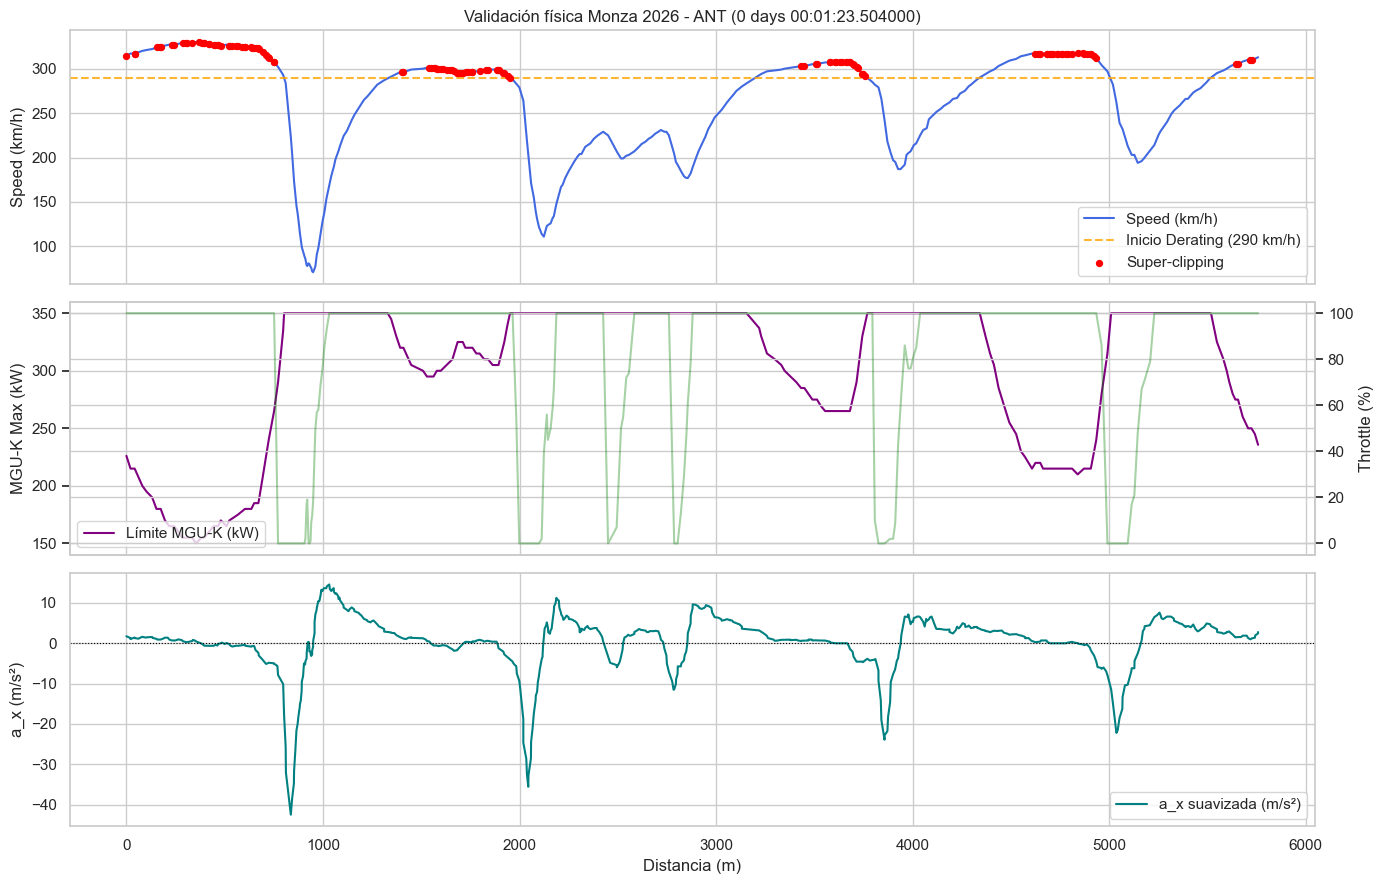

In [6]:
# 1. Suavizado ligero para reducir el ruido de muestreo al derivar dv/dt
df_telemetry["a_x_smooth"] = df_telemetry["a_x"].rolling(window=5, center=True, min_periods=1).mean()

print("Resumen a_x original vs suavizada (m/s²):")
display(df_telemetry[["a_x", "a_x_smooth"]].describe().round(2))

# 2. Gráfico de validación física de la vuelta
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

# Velocidad + puntos detectados como super-clipping
axes[0].plot(df_telemetry["Distance"], df_telemetry["Speed"], color="royalblue", label="Speed (km/h)")
axes[0].axhline(290, color="orange", linestyle="--", alpha=0.8, label="Inicio Derating (290 km/h)")
clip_pts = df_telemetry[df_telemetry["super_clipping"]]
axes[0].scatter(clip_pts["Distance"], clip_pts["Speed"], color="red", s=18, zorder=5, label="Super-clipping")
axes[0].set_ylabel("Speed (km/h)")
axes[0].set_title(f"Validación física Monza 2026 - {fastest_lap['Driver']} ({fastest_lap['LapTime']})")
axes[0].legend(loc="lower right")

# Límite teórico MGU-K (kW) + Throttle (%)
axes[1].plot(df_telemetry["Distance"], df_telemetry["mguk_limit_kw"], color="purple", label="Límite MGU-K (kW)")
axes[1].set_ylabel("MGU-K Max (kW)")
ax1_twin = axes[1].twinx()
ax1_twin.plot(df_telemetry["Distance"], df_telemetry["Throttle"], color="green", alpha=0.35, label="Throttle (%)")
ax1_twin.set_ylabel("Throttle (%)")
axes[1].legend(loc="lower left")

# Aceleración longitudinal suavizada
axes[2].plot(df_telemetry["Distance"], df_telemetry["a_x_smooth"], color="teal", label="a_x suavizada (m/s²)")
axes[2].axhline(0, color="black", linewidth=0.8, linestyle=":")
axes[2].set_ylabel("a_x (m/s²)")
axes[2].set_xlabel("Distancia (m)")
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.show()

### Interpretación física de la vuelta de referencia

* **Validación del suavizado (`a_x_smooth`):** Al aplicar una media móvil de 5 muestras se eliminan los picos de ruido derivados de `dt` irregulares. La aceleración máxima pasa a **14.58 m/s²** (~1.49 G a la salida de la *Prima Variante*) y los cuatro picos de deceleración (**-42.5, -35, -24 y -22 m/s²**) coinciden con las frenadas reales de Monza (*Prima Variante*, *Roggia*, *Ascari* y *Parabolica*).
* **Zonas de *derating* (> 290 km/h):** En las cuatro rectas principales se supera el umbral de 290 km/h, cayendo el límite teórico del MGU-K desde 350 kW hasta **~150 kW** a 330 km/h en la recta de meta.
* ***Super-clipping* vs. equilibrio aerodinámico:** Se observa especialmente en la recta hacia la *Variante della Roggia* (~1550–1750 m), donde la velocidad cae ligeramente (de ~300 a ~295 km/h) manteniendo el acelerador al 100 % (`a_x` negativa en torno a -1.5 m/s²), señal clara de recuperación energética en recta.

In [7]:
# Filtrado de vueltas limpias en Carrera (bandera verde, sin pit-stops, sin salida)
clean_laps_r = session.laps[
    (session.laps["LapNumber"] > 1)
    & (session.laps["PitInTime"].isna())
    & (session.laps["PitOutTime"].isna())
    & (session.laps["TrackStatus"] == "1")
    & (session.laps["LapTime"].notna())
].copy()

print(f"Vueltas totales en la sesión: {len(session.laps)}")
print(f"Vueltas limpias tras el filtro: {len(clean_laps_r)}")
print(f"Pilotos con vueltas limpias: {clean_laps_r['Driver'].nunique()}")

# Resumen por equipo y piloto
clean_laps_r.groupby(["Team", "Driver"])["LapNumber"].count().sort_values(ascending=False)

Vueltas totales en la sesión: 1054
Vueltas limpias tras el filtro: 889
Pilotos con vueltas limpias: 21


Team             Driver
Alpine           COL       46
Audi             BOR       46
McLaren          PIA       46
Haas F1 Team     BEA       46
Ferrari          HAM       46
Red Bull Racing  VER       46
Mercedes         RUS       46
Alpine           GAS       45
Mercedes         ANT       45
Williams         SAI       45
McLaren          NOR       45
Haas F1 Team     OCO       45
Audi             HUL       45
Racing Bulls     LIN       45
Cadillac         PER       44
Racing Bulls     TSU       44
Cadillac         BOT       43
Red Bull Racing  LAW       43
Williams         ALB       42
Aston Martin     STR       20
                 ALO       16
Name: LapNumber, dtype: int64

In [8]:
# Cargar Clasificación de Monza 2026
session_q = fastf1.get_session(2026, 13, "Q")
session_q.load()

# Filtrar vueltas lanzadas limpias (dentro del 107% de la más rápida, bandera verde, sin pit)
clean_laps_q = session_q.laps.pick_quicklaps()
clean_laps_q = clean_laps_q[
    (clean_laps_q["PitInTime"].isna())
    & (clean_laps_q["PitOutTime"].isna())
    & (clean_laps_q["TrackStatus"] == "1")
    & (clean_laps_q["LapTime"].notna())
].copy()

print(f"Vueltas totales en Q: {len(session_q.laps)}")
print(f"Vueltas lanzadas limpias en Q: {len(clean_laps_q)}")
print(f"Pilotos en Q con vueltas limpias: {clean_laps_q['Driver'].nunique()}")

core           INFO 	Loading data for Italian Grand Prix - Qualifying [v3.9.2]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for _extended_timing_data. Loading data...
_api           INFO 	Fetching timing data...
_api           INFO 	Parsing timing data...
req            INFO 

Vueltas totales en Q: 307
Vueltas lanzadas limpias en Q: 97
Pilotos en Q con vueltas limpias: 22


In [9]:
def calculate_mguk_max_power(speed_kmh):
    if speed_kmh <= 290:
        return 350.0
    elif speed_kmh < 340:
        return max(0.0, 1800.0 - 5.0 * speed_kmh)
    elif speed_kmh <= 345:
        return max(0.0, 6900.0 - 20.0 * speed_kmh)
    return 0.0


def extract_session_microsectors(laps_df, session_label, sector_len_m=50):
    records = []
    for _, lap in laps_df.iterlaps():
        try:
            tel = lap.get_telemetry()
        except Exception:
            continue
        if tel.empty or len(tel) < 20:
            continue

        tel = tel.copy()
        tel["dt"] = tel["Time"].dt.total_seconds().diff().fillna(0).clip(lower=0)
        tel["Speed_ms"] = tel["Speed"] / 3.6
        dv = tel["Speed_ms"].diff().fillna(0)
        # Evitar división por cero cuando dt == 0
        raw_ax = np.where(tel["dt"] > 1e-3, dv / tel["dt"], 0.0)
        tel["a_x_smooth"] = pd.Series(raw_ax, index=tel.index).rolling(5, center=True, min_periods=1).mean()

        tel["mguk_limit_kw"] = tel["Speed"].apply(calculate_mguk_max_power)
        tel["in_derating_zone"] = (tel["Speed"] > 290).astype(float)
        tel["full_throttle"] = (tel["Throttle"] >= 99.0).astype(float)
        tel["super_clipping"] = (
            (tel["Throttle"] >= 99.0) & (tel["Speed"] > 290) & (tel["a_x_smooth"] <= 0.2)
        ).astype(float)

        # Proxy de Modo Override (< 1 segundo del coche precedente)
        gap_s = tel["DistanceToDriverAhead"] / tel["Speed_ms"].clip(lower=5.0)
        tel["override_candidate"] = (gap_s.notna() & (gap_s <= 1.0)).astype(float)

        tel["micro_sector"] = (tel["Distance"] // sector_len_m).astype(int)

        agg = tel.groupby("micro_sector", as_index=False).agg(
            speed_mean=("Speed", "mean"),
            speed_max=("Speed", "max"),
            speed_min=("Speed", "min"),
            ax_mean=("a_x_smooth", "mean"),
            ax_min=("a_x_smooth", "min"),
            throttle_mean=("Throttle", "mean"),
            brake_pct=("Brake", "mean"),
            rpm_mean=("RPM", "mean"),
            gear_mean=("nGear", "mean"),
            mguk_limit_mean=("mguk_limit_kw", "mean"),
            derating_pct=("in_derating_zone", "mean"),
            super_clipping_pct=("super_clipping", "mean"),
            override_pct=("override_candidate", "mean"),
            sector_time_s=("dt", "sum"),
        )

        agg["SessionType"] = session_label
        agg["Driver"] = lap["Driver"]
        agg["Team"] = lap["Team"]
        agg["LapNumber"] = int(lap["LapNumber"])
        agg["Compound"] = lap["Compound"]
        agg["LapTime_s"] = lap["LapTime"].total_seconds()
        records.append(agg)

    return pd.concat(records, ignore_index=True)

In [10]:
df_q = extract_session_microsectors(clean_laps_q, "Q")
df_r = extract_session_microsectors(clean_laps_r, "R")
df_micro = pd.concat([df_q, df_r], ignore_index=True)

processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)
df_micro.to_parquet(processed_dir / "monza_2026_microsectors.parquet", index=False)

print(f"Dataset final de micro-sectores: {df_micro.shape}")
df_micro.head()

Dataset final de micro-sectores: (114278, 21)


,micro_sector,speed_mean,speed_max,speed_min,ax_mean,ax_min,throttle_mean,brake_pct,rpm_mean,gear_mean,...,derating_pct,super_clipping_pct,override_pct,sector_time_s,SessionType,Driver,Team,LapNumber,Compound,LapTime_s
0,0,309.027776,311.000000,306.520832,3.793728,3.665126,100.0,0.0,10718.105523,8.0,...,1.0,0.0,0.0,0.215,Q,GAS,Alpine,2,SOFT,82.612
1,1,317.508333,321.000000,315.000000,4.340281,3.858026,100.0,0.0,10993.634708,8.0,...,1.0,0.0,0.0,0.720,Q,GAS,Alpine,2,SOFT,82.612
2,2,325.996180,328.000000,323.000000,3.458448,2.414027,100.0,0.0,11239.939924,8.0,...,1.0,0.0,0.0,0.640,Q,GAS,Alpine,2,SOFT,82.612
3,3,330.966607,332.221429,329.792856,1.825398,1.686509,100.0,0.0,11385.917930,8.0,...,1.0,0.0,0.0,0.631,Q,GAS,Alpine,2,SOFT,82.612
4,4,334.560714,335.000000,334.000000,1.173942,0.793651,100.0,0.0,11500.896430,8.0,...,1.0,0.0,0.0,0.529,Q,GAS,Alpine,2,SOFT,82.612


### Almacenamiento en formato Parquet (`.parquet`)
Guardamos el dataset procesado en **Apache Parquet** en lugar de CSV por tres motivos:
* **Compresión columnar:** ocupa bastante menos espacio en disco que un CSV plano.
* **Rendimiento de E/S:** permite lectura y escritura mucho más rápidas, además de cargar únicamente las columnas necesarias.
* **Integridad de tipos (`dtypes`):** conserva exactamente los tipos numéricos y categóricos sin tener que re-inferirlos al recargar el notebook.

In [11]:
print("Nulos por columna:")
print(df_micro.isna().sum()[df_micro.isna().sum() > 0])

print("\nDistribución por sesión:")
print(df_micro["SessionType"].value_counts())

print("\nMicro-sectores con candidato a Override (override_pct > 0):", (df_micro["override_pct"] > 0).sum())
print("Micro-sectores con Super-clipping (super_clipping_pct > 0):", (df_micro["super_clipping_pct"] > 0).sum())

df_micro.describe().T[["count", "mean", "min", "50%", "max"]].round(2)

Nulos por columna:
Series([], dtype: int64)

Distribución por sesión:
SessionType
R    103035
Q     11243
Name: count, dtype: int64

Micro-sectores con candidato a Override (override_pct > 0): 32551
Micro-sectores con Super-clipping (super_clipping_pct > 0): 24040


,count,mean,min,50%,max
micro_sector,114278.0,57.55,-1.00,58.00,120.00
speed_mean,114278.0,260.23,48.92,282.09,350.99
speed_max,114278.0,265.83,62.37,285.16,351.00
speed_min,114278.0,255.01,37.00,279.00,350.98
ax_mean,114278.0,0.21,-84.38,0.94,42.11
ax_min,114278.0,-1.43,-146.78,0.56,23.26
throttle_mean,114278.0,84.47,0.00,100.00,104.00
brake_pct,114278.0,0.11,0.00,0.00,1.00
rpm_mean,114278.0,10934.13,4185.88,10997.02,12797.77
gear_mean,114278.0,6.49,0.00,7.00,8.00


En la tabla podemos ver algunos valores anomalos o que no encajan con lo que deberia ser la realidad:

1. `micro_sector = 1` y `sector_time_s = 0.00`: Esto ocurre justo sobre la linea de meta. A tan altas velocidades, el coche recorre 50 metros muy rápido asi que cualquier tramo con los mismos valores, es un borde incompleto.

2. `ax_mean = -84.38 a 42.11 m/s2` y `ax_min = -146.78 m/s2`: Son artefactos al descargar la telemetria desde FastF1.

3. `throttle_mean` maximo de `104.00`: Error tipico de telemetria (ya sea de algun sensor o de FastF1). Acotar entre 0 y 100

In [12]:
df_clean = df_micro[
    (df_micro["micro_sector"] >= 0)
    & (df_micro["sector_time_s"] >= 0.1)
].copy()

# Acotar valores físicamente imposibles por ruido de muestreo
df_clean["throttle_mean"] = df_clean["throttle_mean"].clip(0, 100)
df_clean["ax_mean"] = df_clean["ax_mean"].clip(-55, 25)
df_clean["ax_min"] = df_clean["ax_min"].clip(-55, 25)

print(f"Filas antes: {len(df_micro):,} | Filas limpias: {len(df_clean):,} "
      f"(descartadas: {len(df_micro) - len(df_clean):,})")

# Actualizar el parquet con la versión saneada
df_clean.to_parquet(processed_dir / "monza_2026_microsectors.parquet", index=False)

df_clean[["speed_mean", "ax_mean", "ax_min", "throttle_mean", "sector_time_s"]].describe().T[["min", "50%", "max"]].round(2)

Filas antes: 114,278 | Filas limpias: 113,949 (descartadas: 329)


,min,50%,max
speed_mean,48.92,281.99,350.99
ax_mean,-55.00,0.94,25.00
ax_min,-55.00,0.56,23.26
throttle_mean,0.00,100.00,100.00
sector_time_s,0.10,0.68,3.72
